In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240612_CAT16_C10_W3_run3.DSC", exp_type="francklab_esr/romana") # cooling 2 --initial sample
d2 = find_file("240612_CAT16_C10_W3_run4.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (20, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (20, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (20, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (20, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling 2 (below transition)')

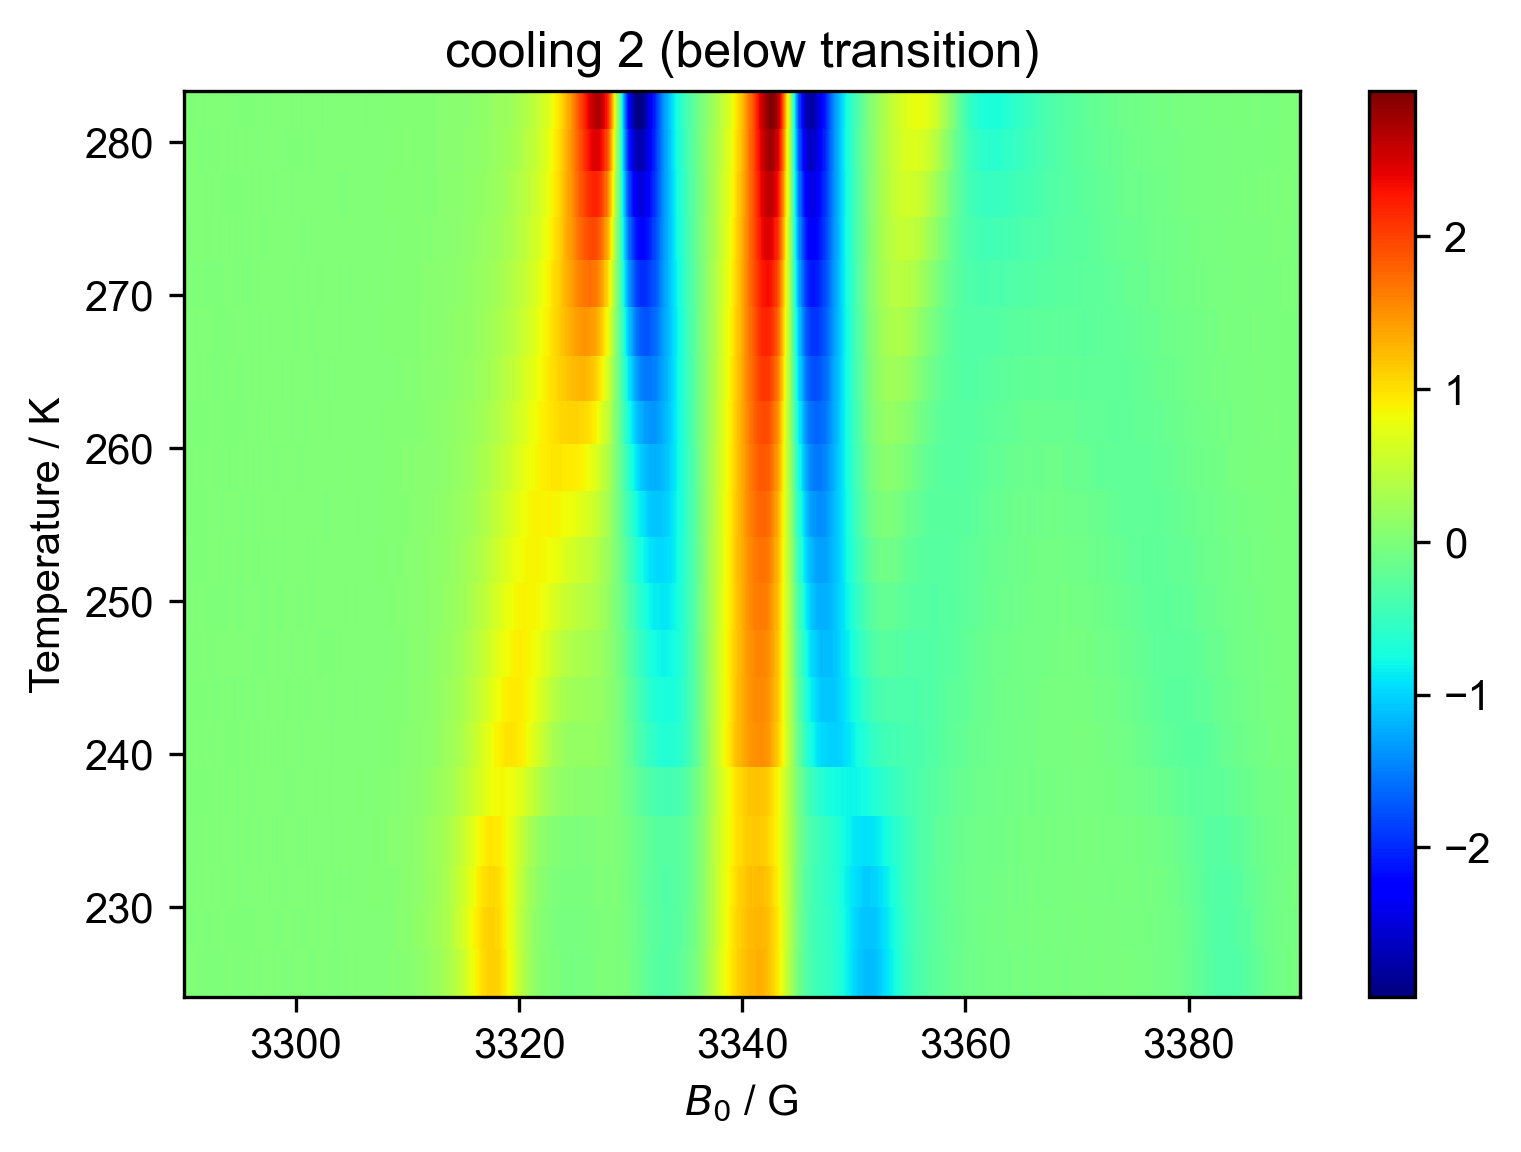

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling 2 (below transition)")

Text(0.5, 1.0, 'heating 2 (below transition)')

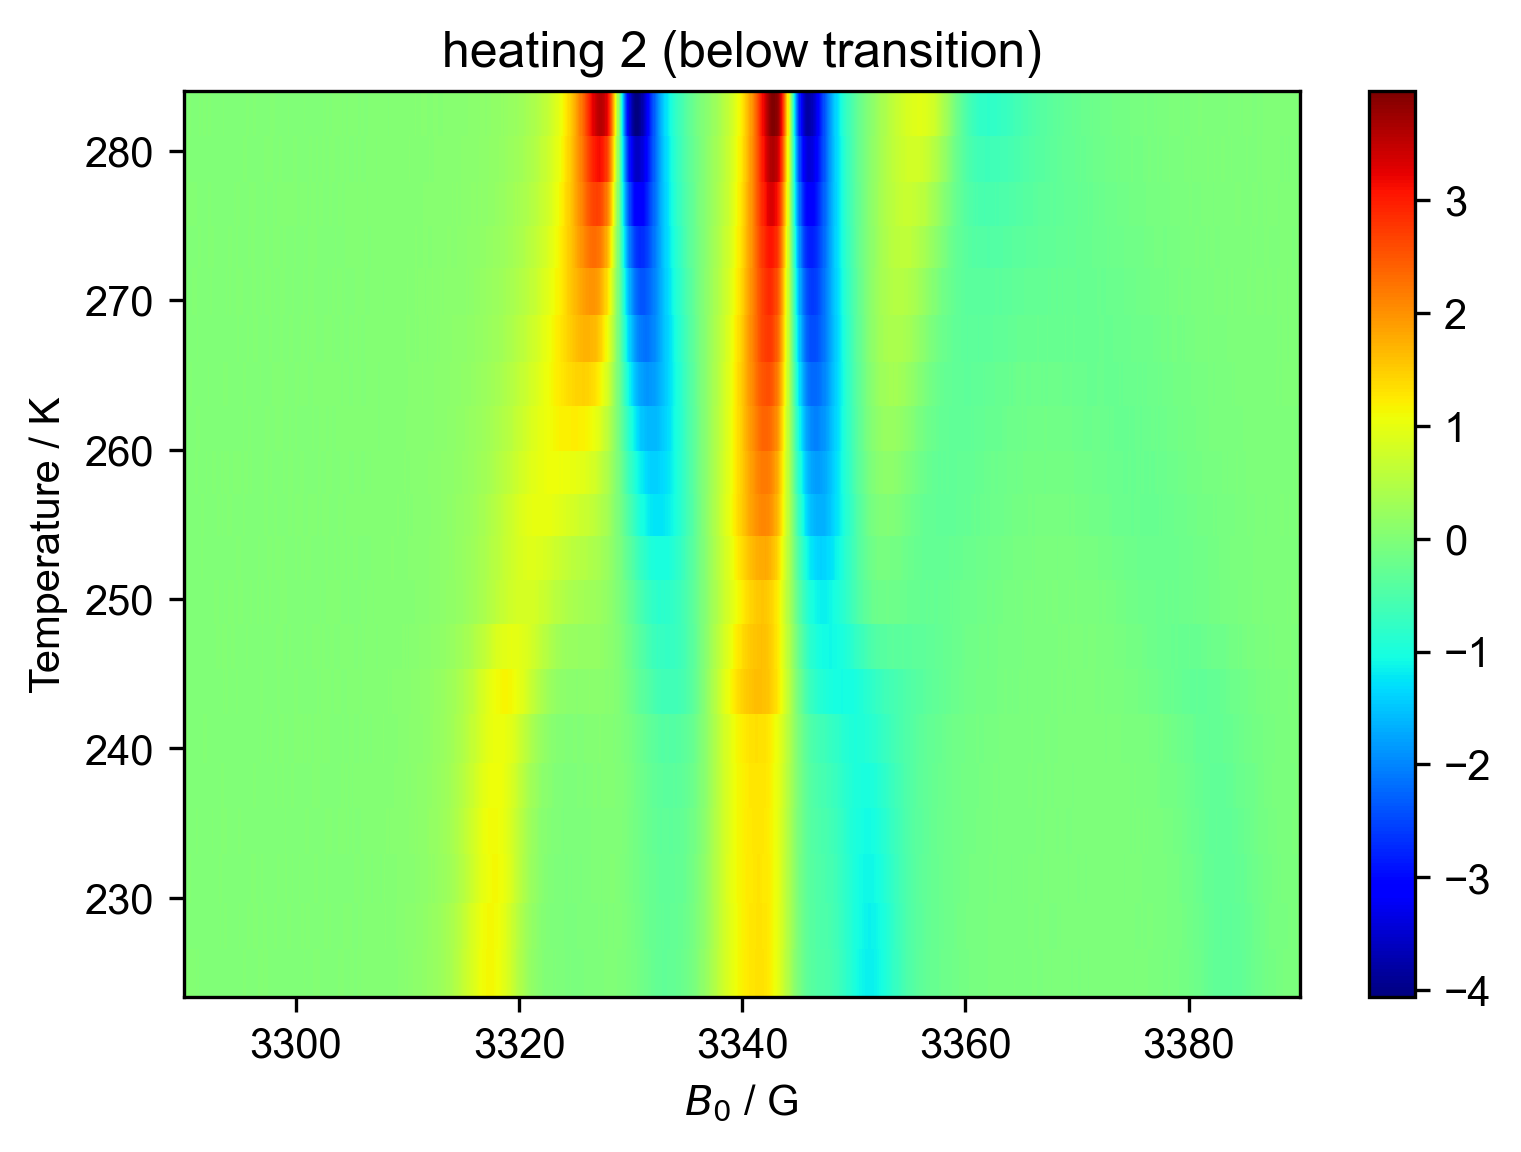

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating 2 (below transition)")

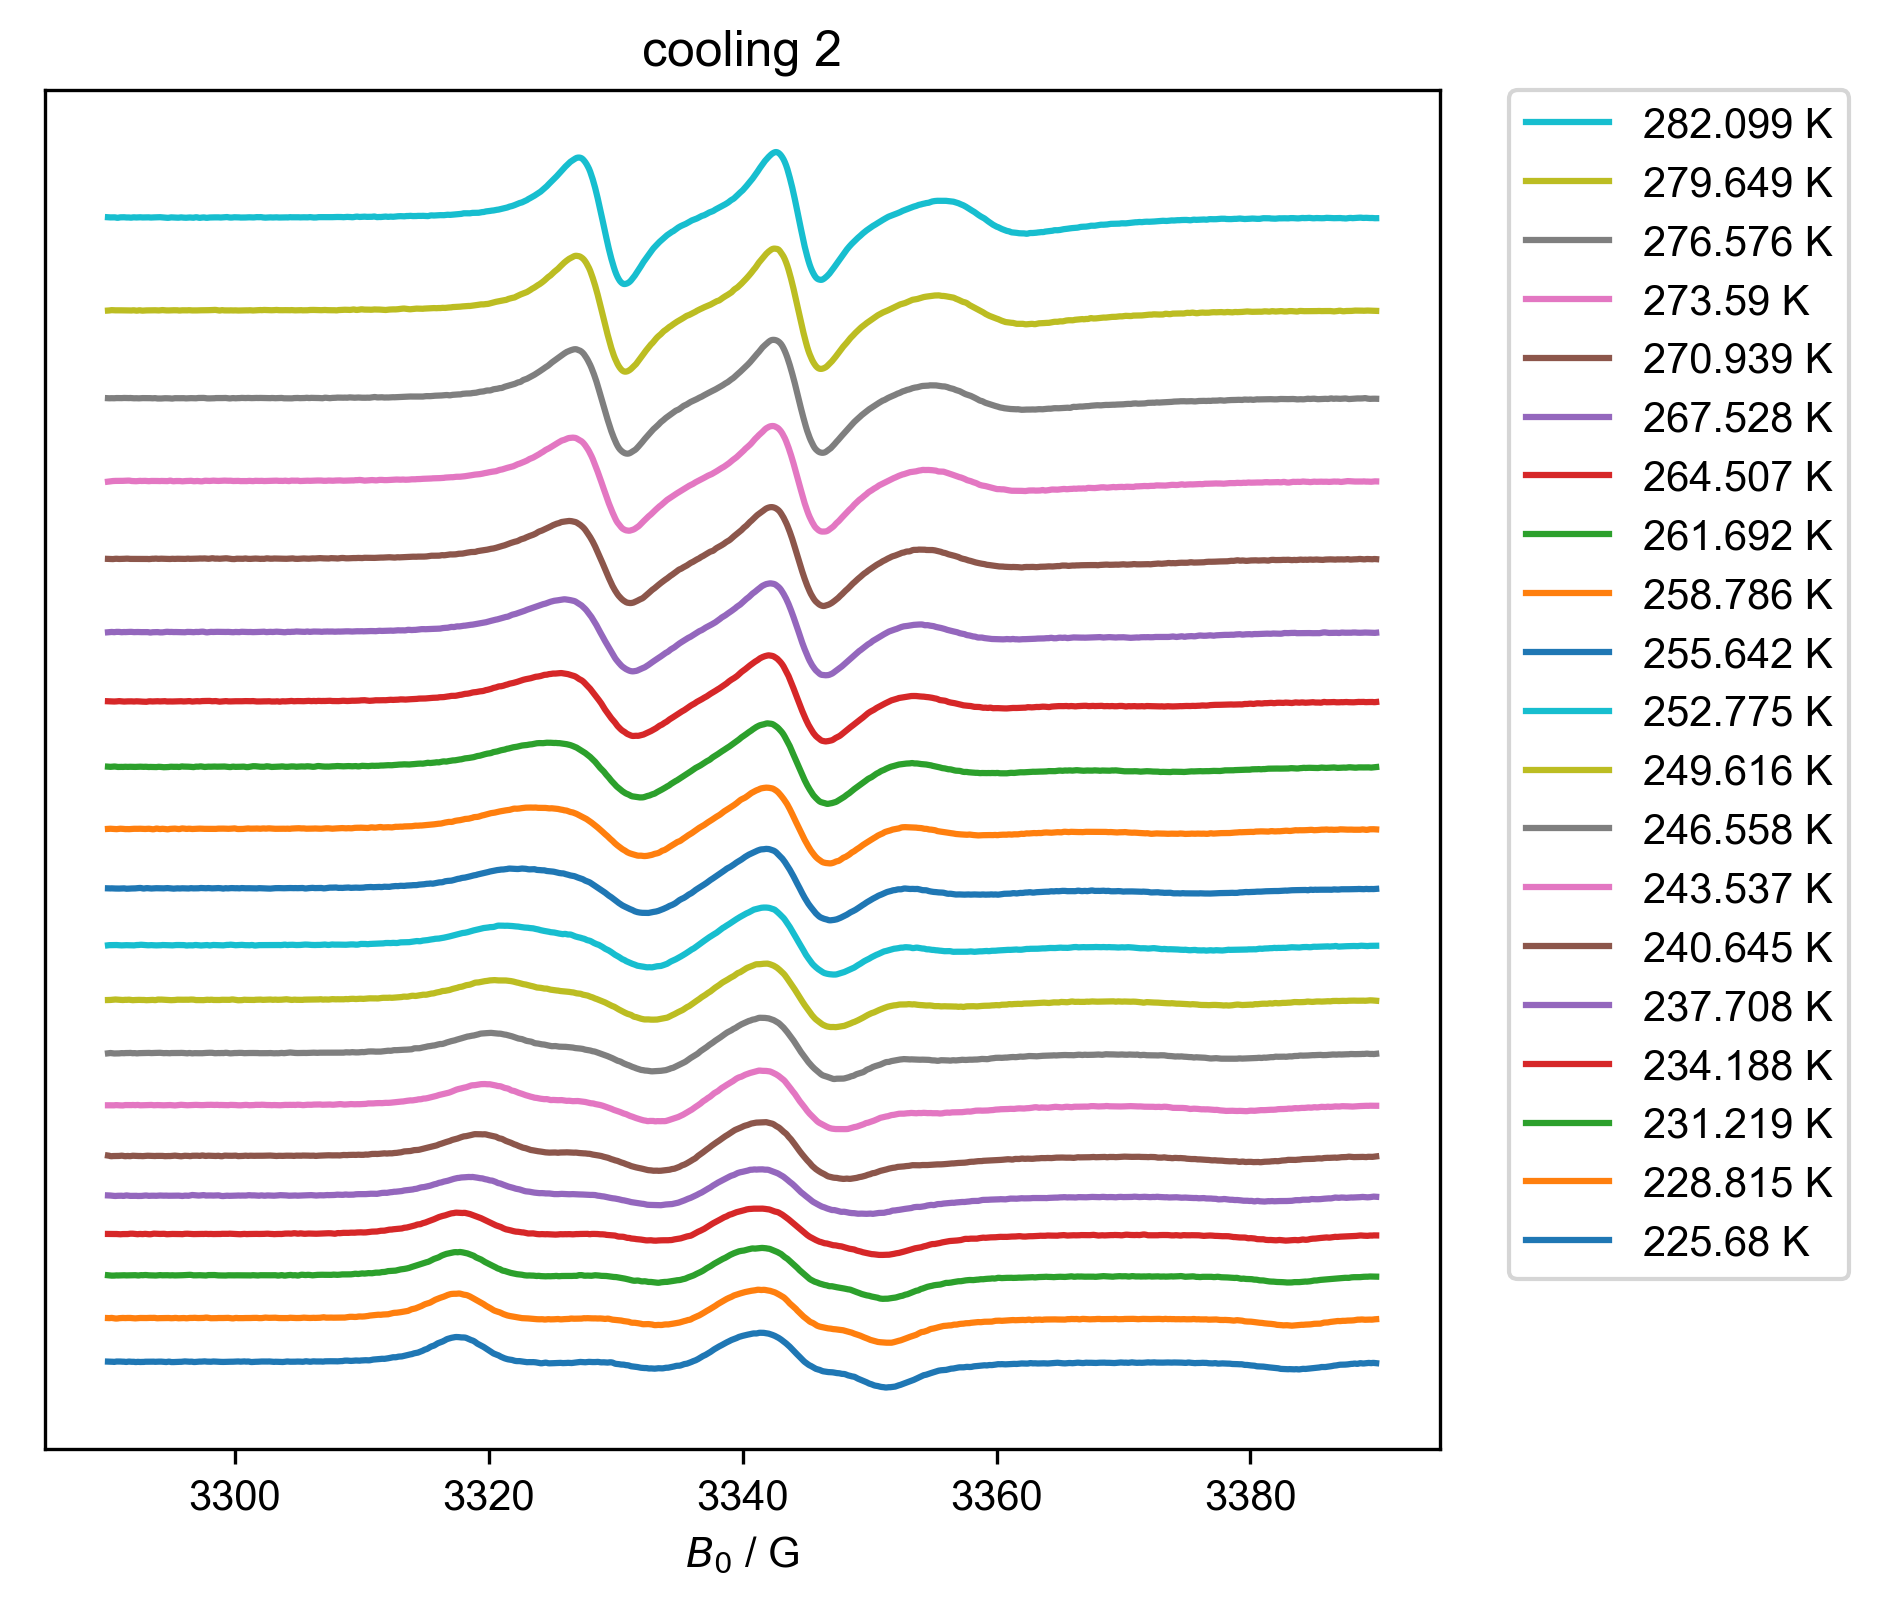

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("cooling 2", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

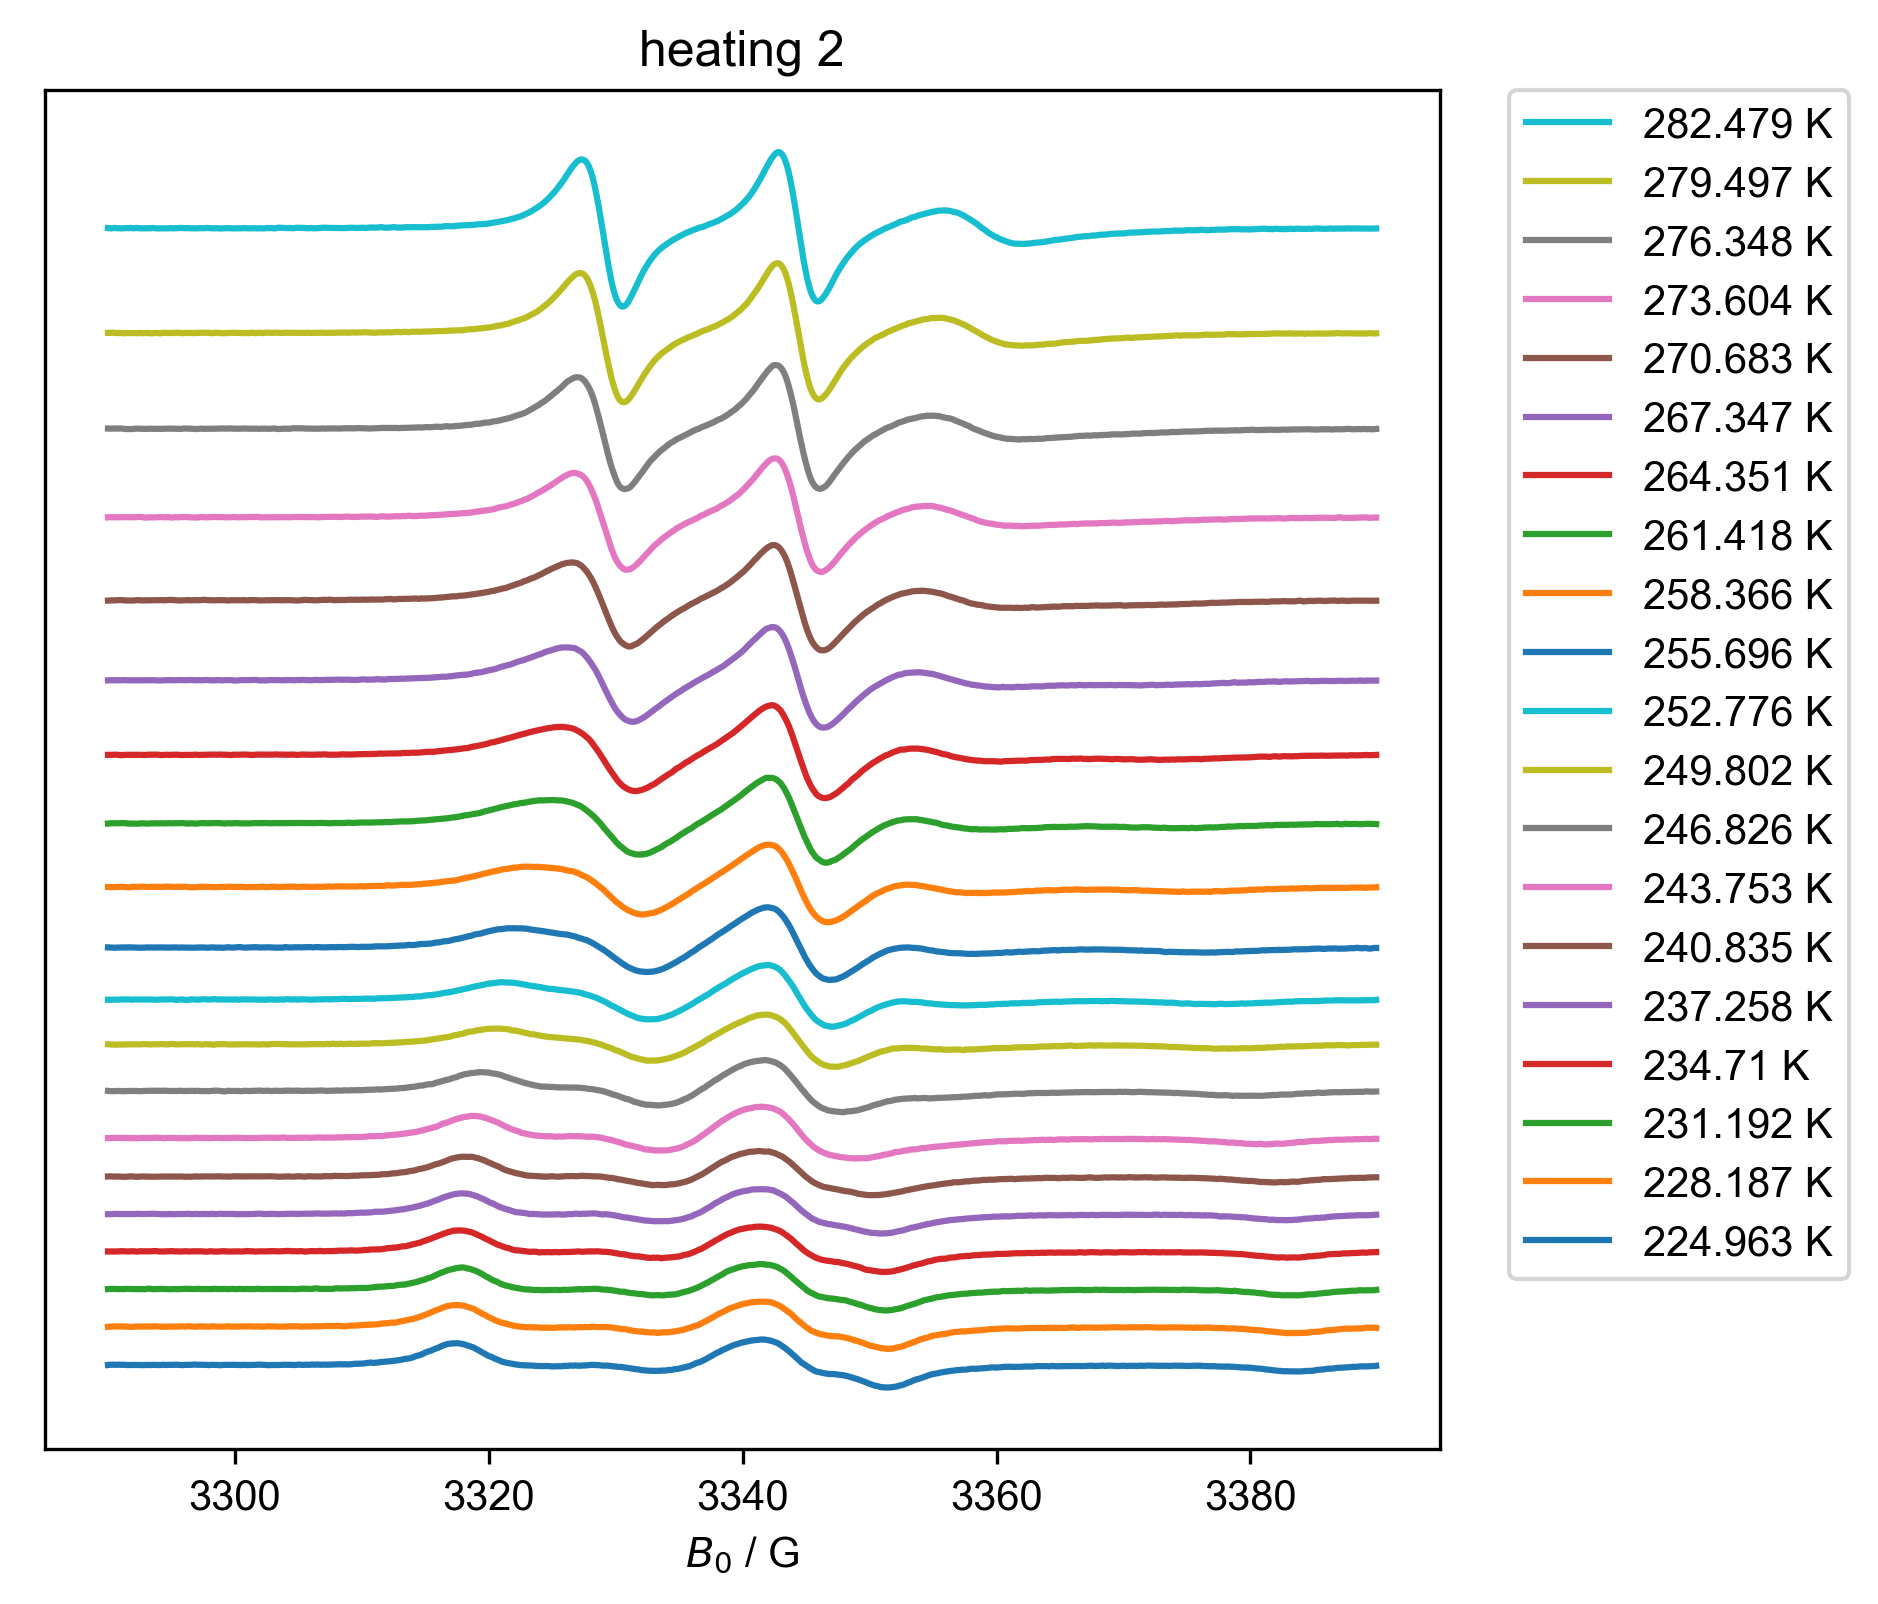

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("heating 2", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


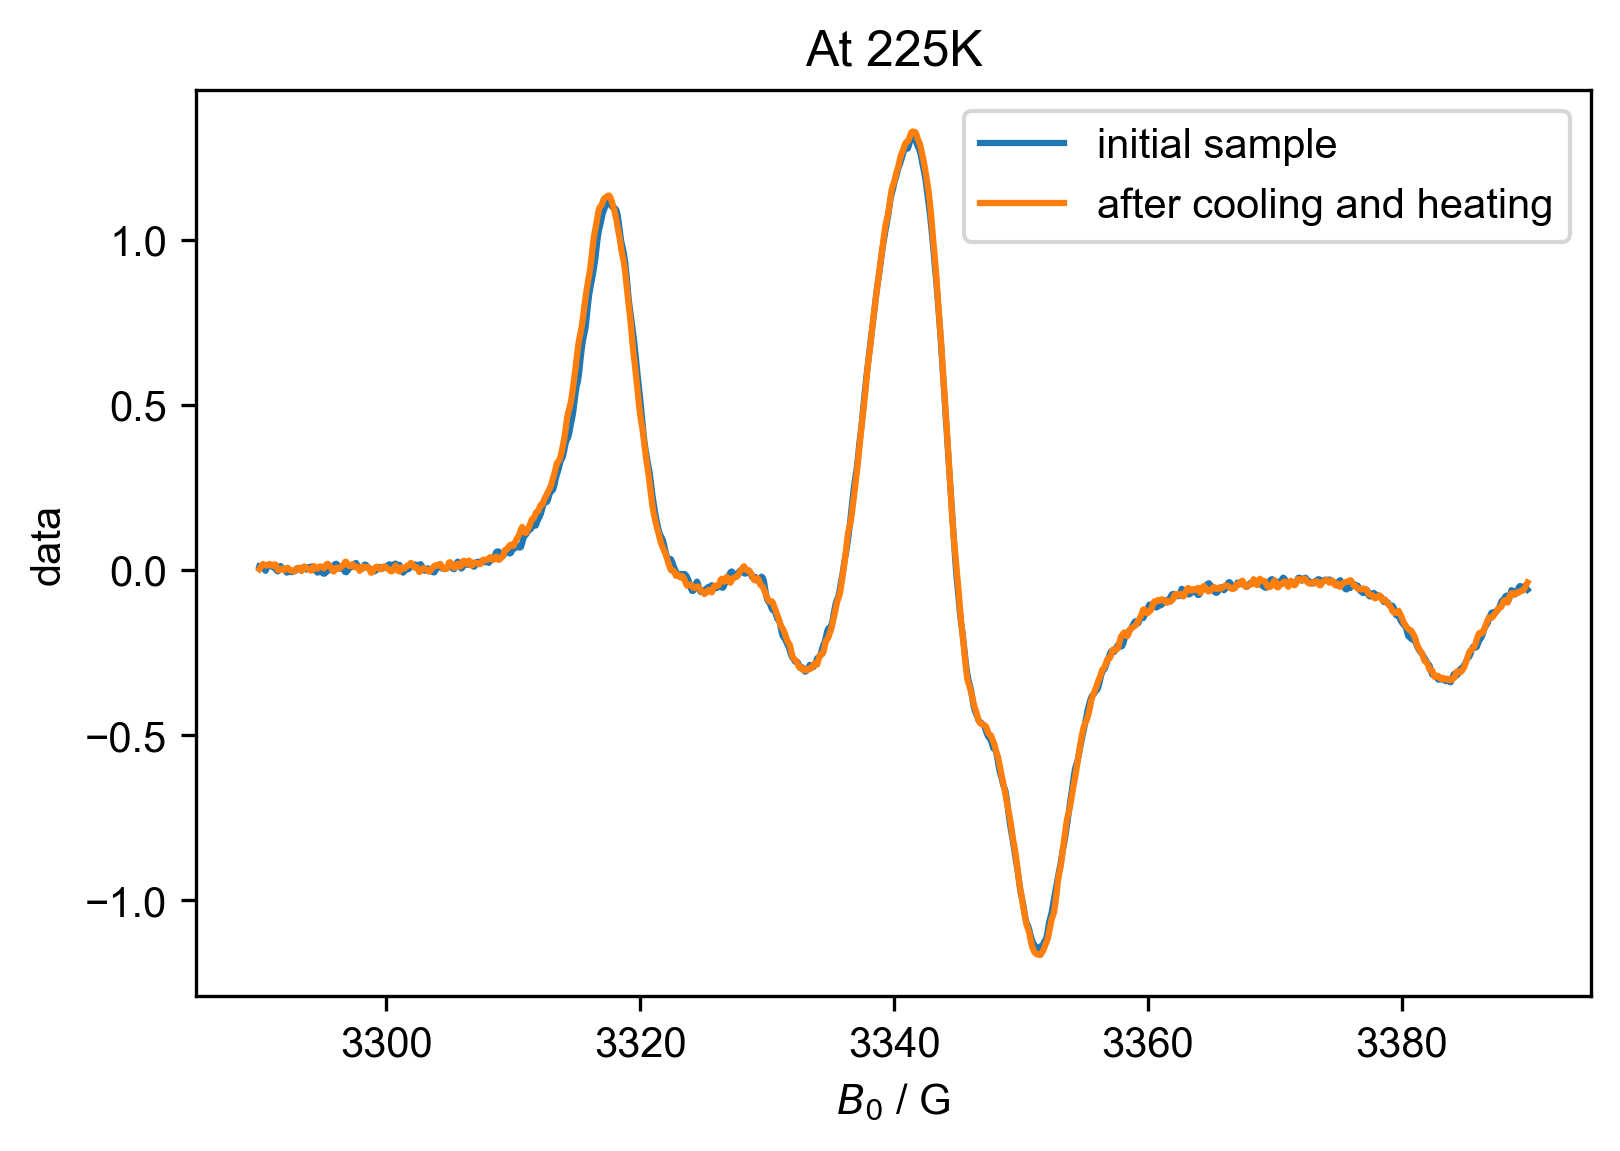

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":225], label="initial sample")
plot(d2["Temperature":225], label="after cooling and heating")
title("At 225K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


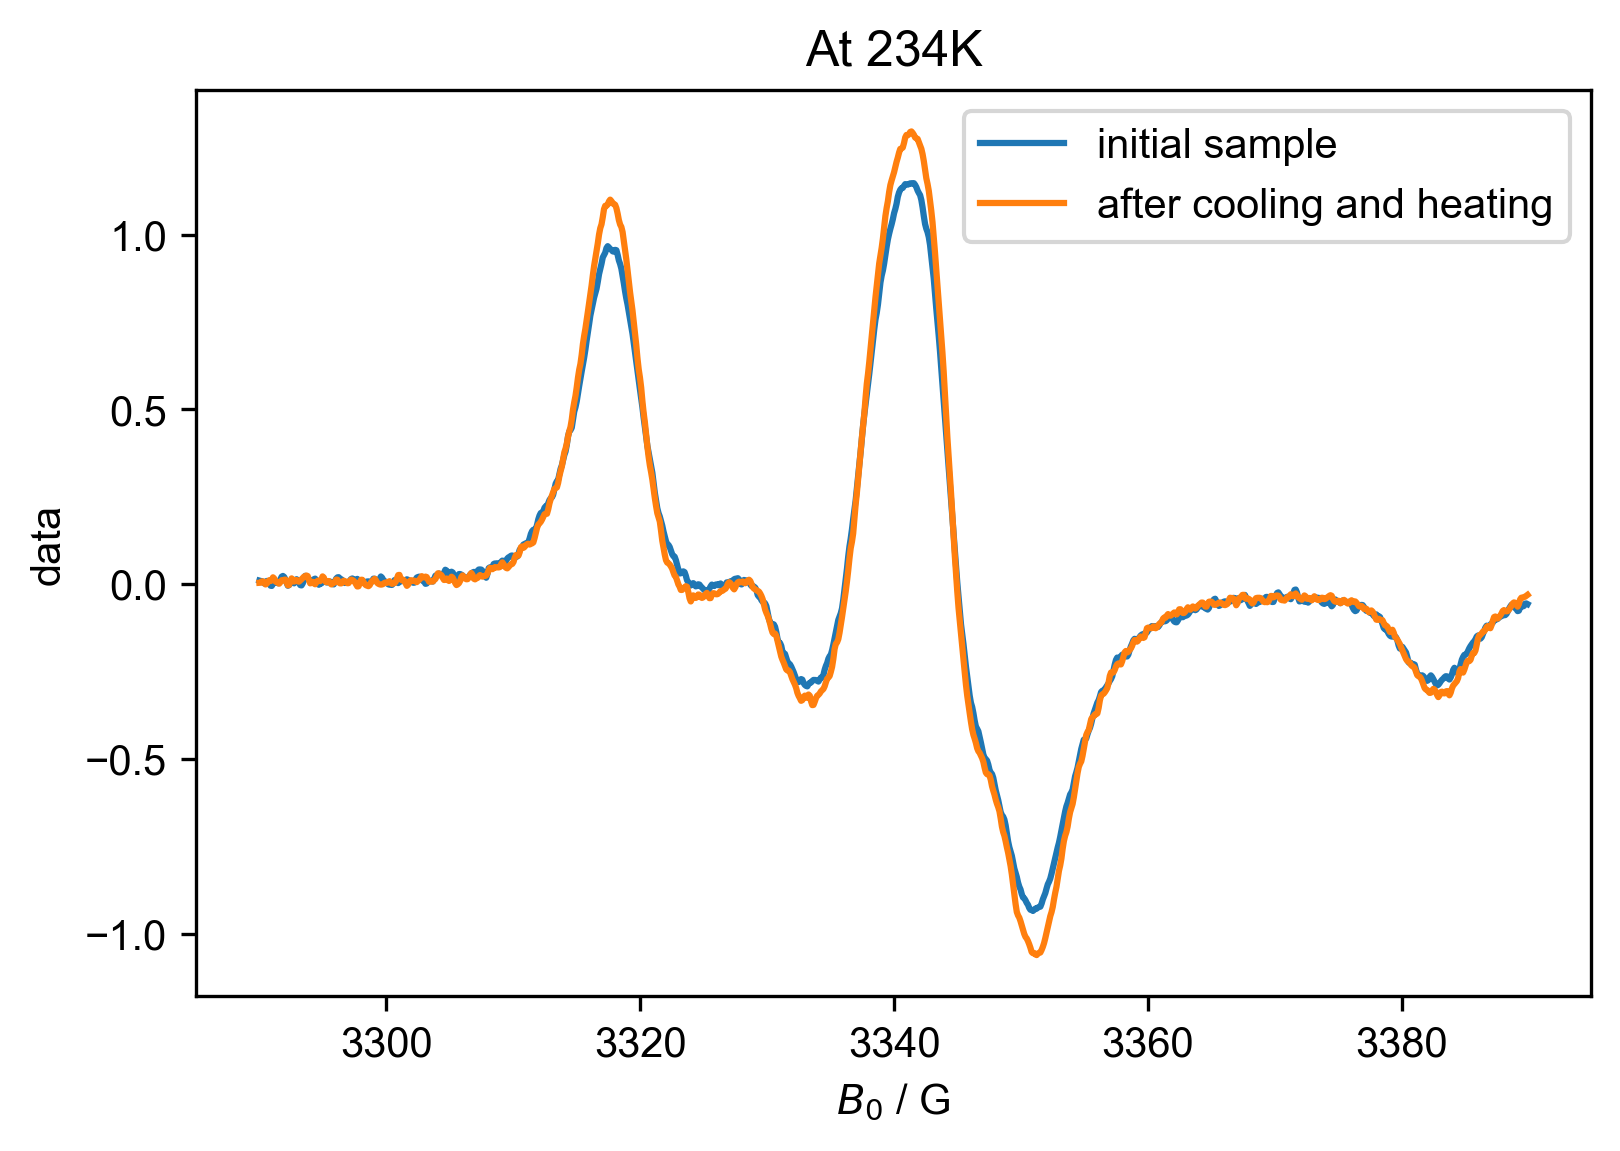

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":234], label="initial sample")
plot(d2["Temperature":234], label="after cooling and heating")
title("At 234K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


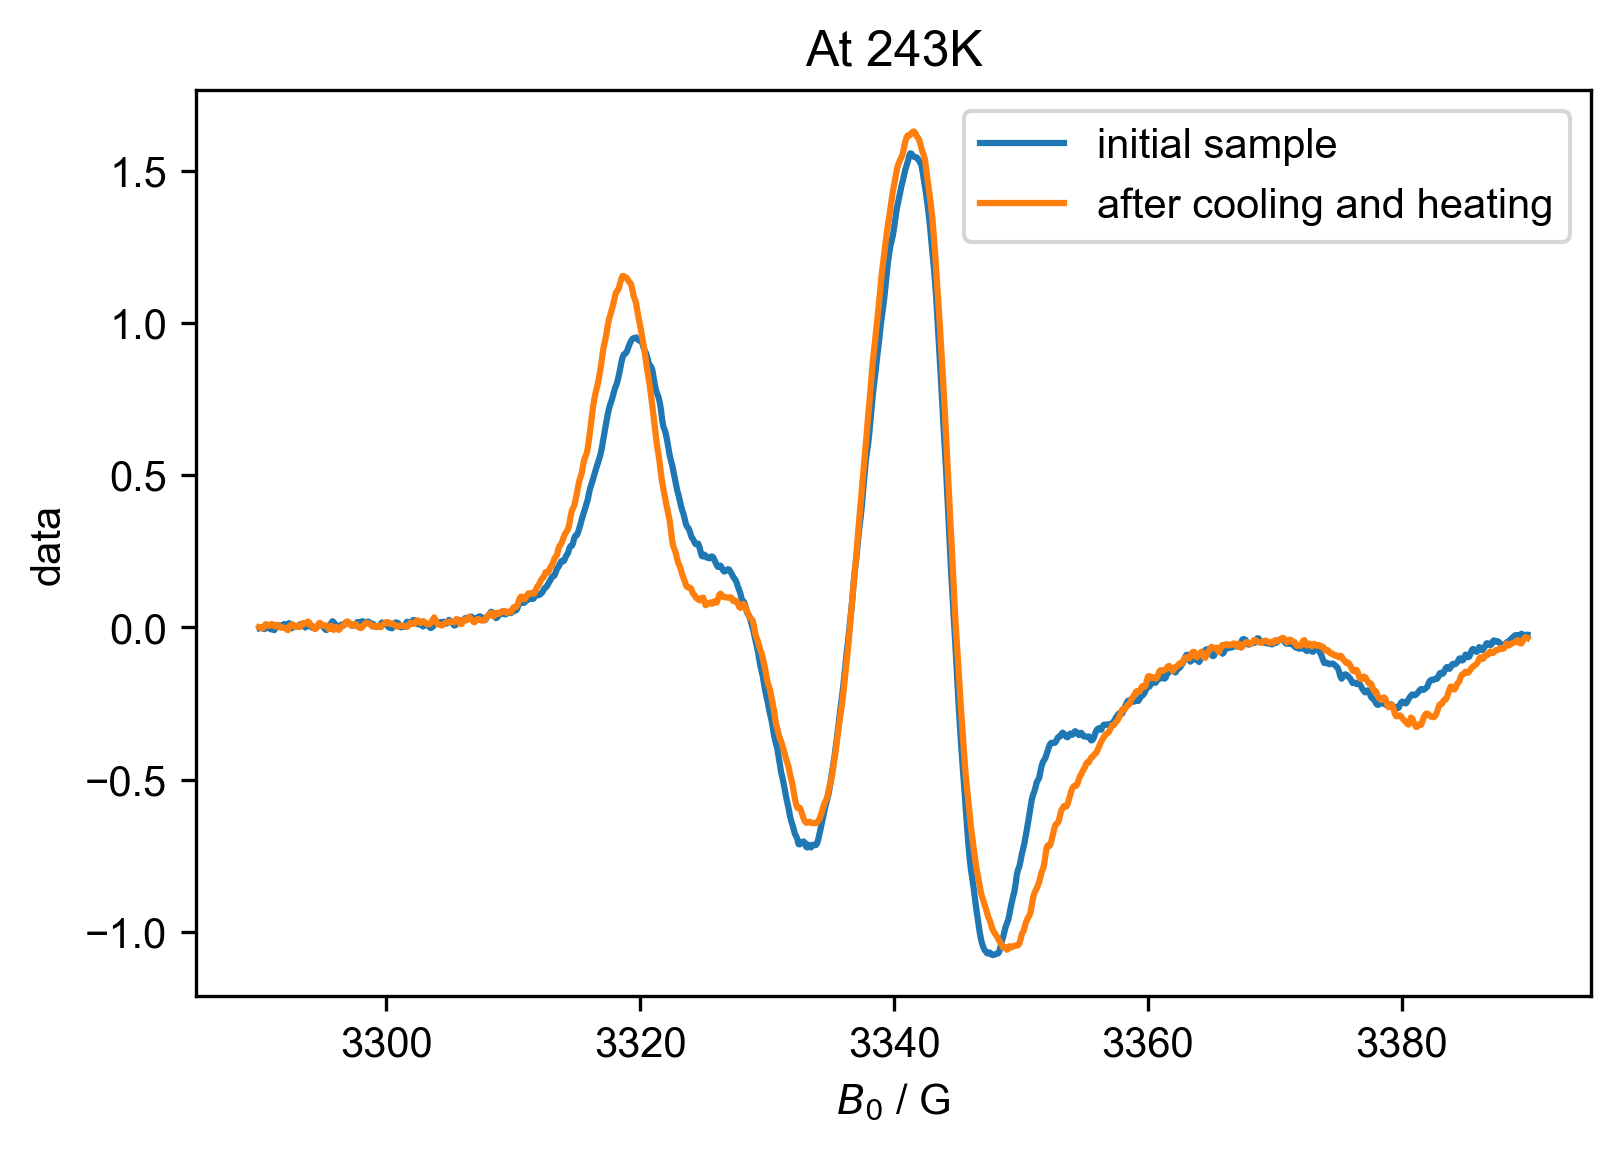

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":243], label="initial sample")
plot(d2["Temperature":243], label="after cooling and heating")
title("At 243K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


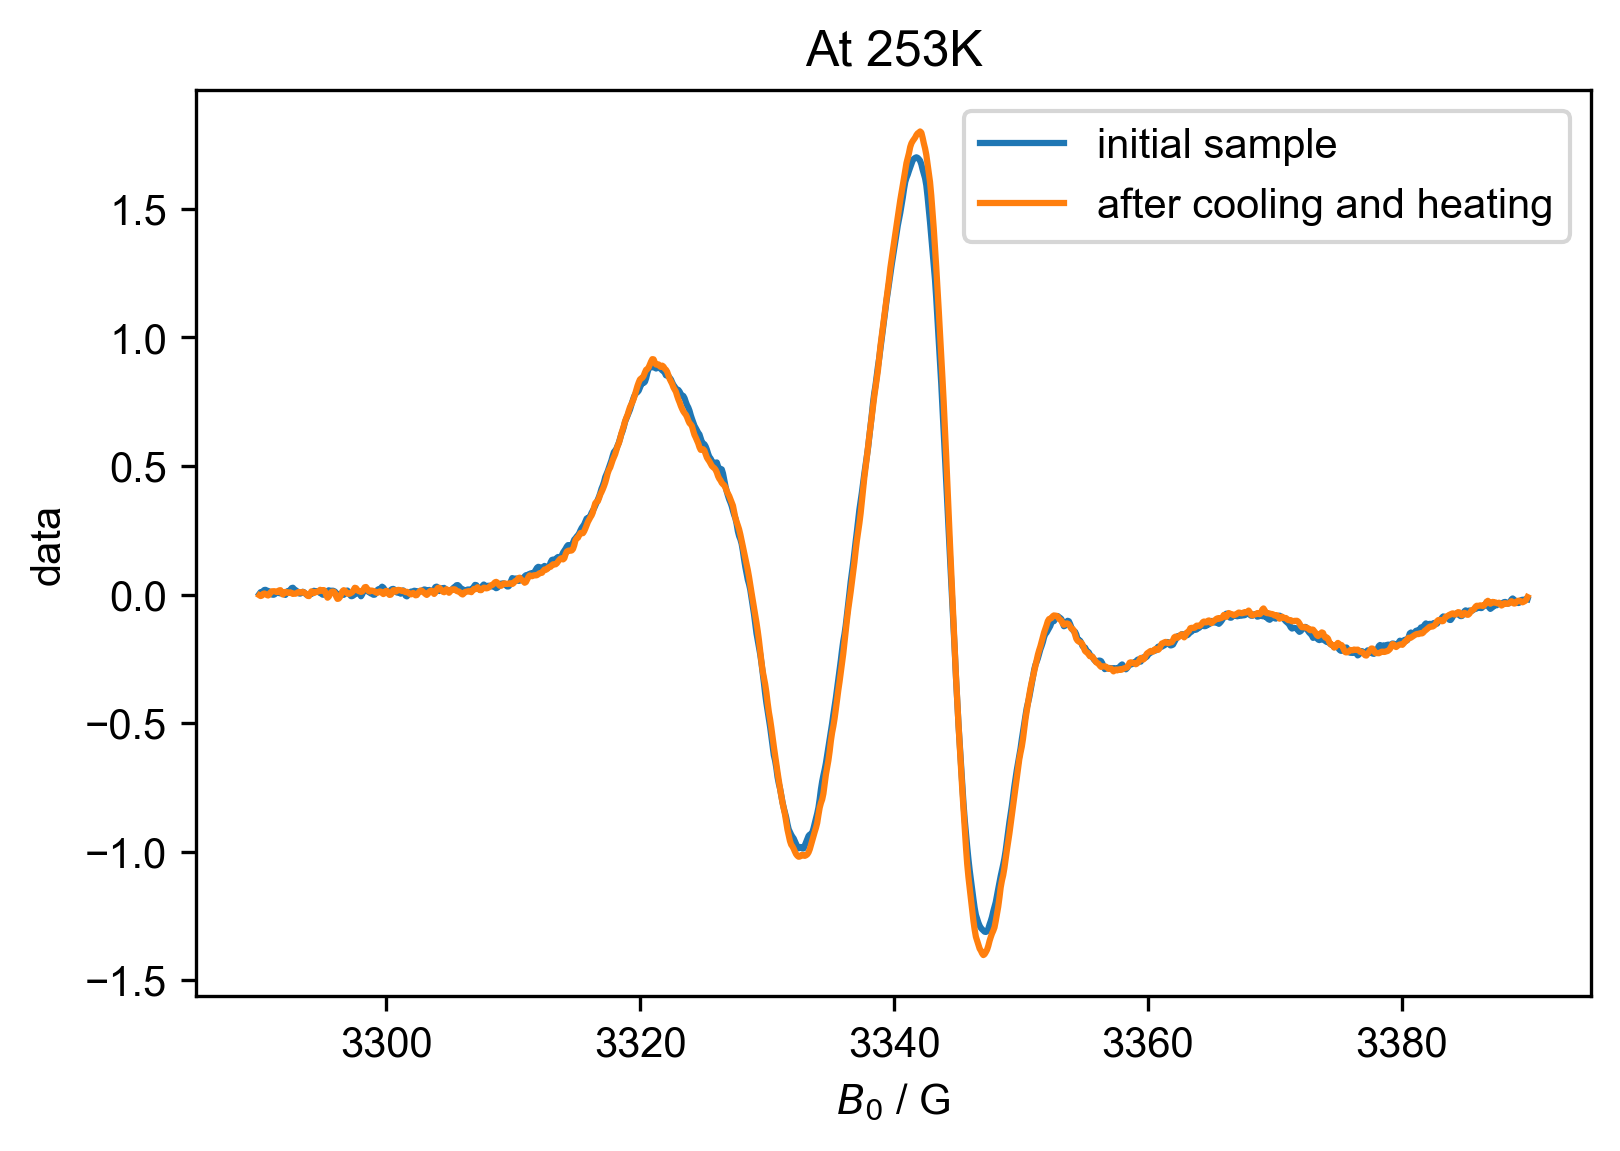

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


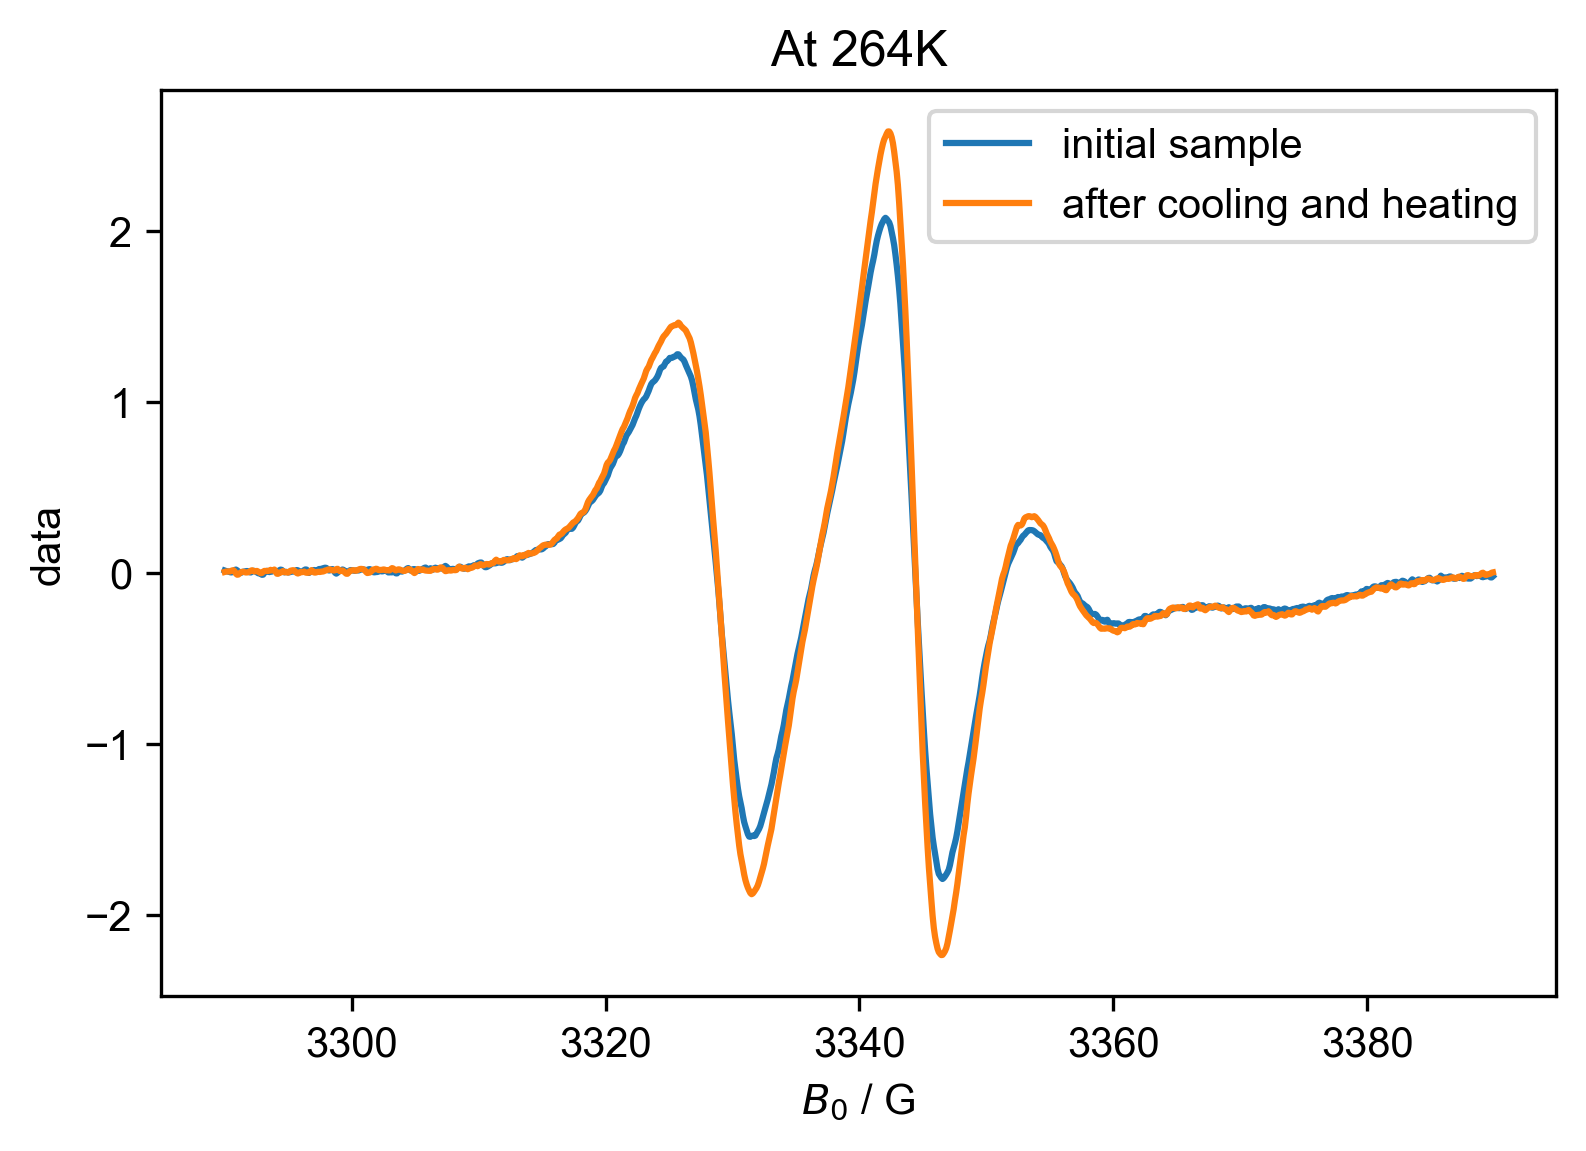

In [15]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":264], label="initial sample")
plot(d2["Temperature":264], label="after cooling and heating")
title("At 264K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


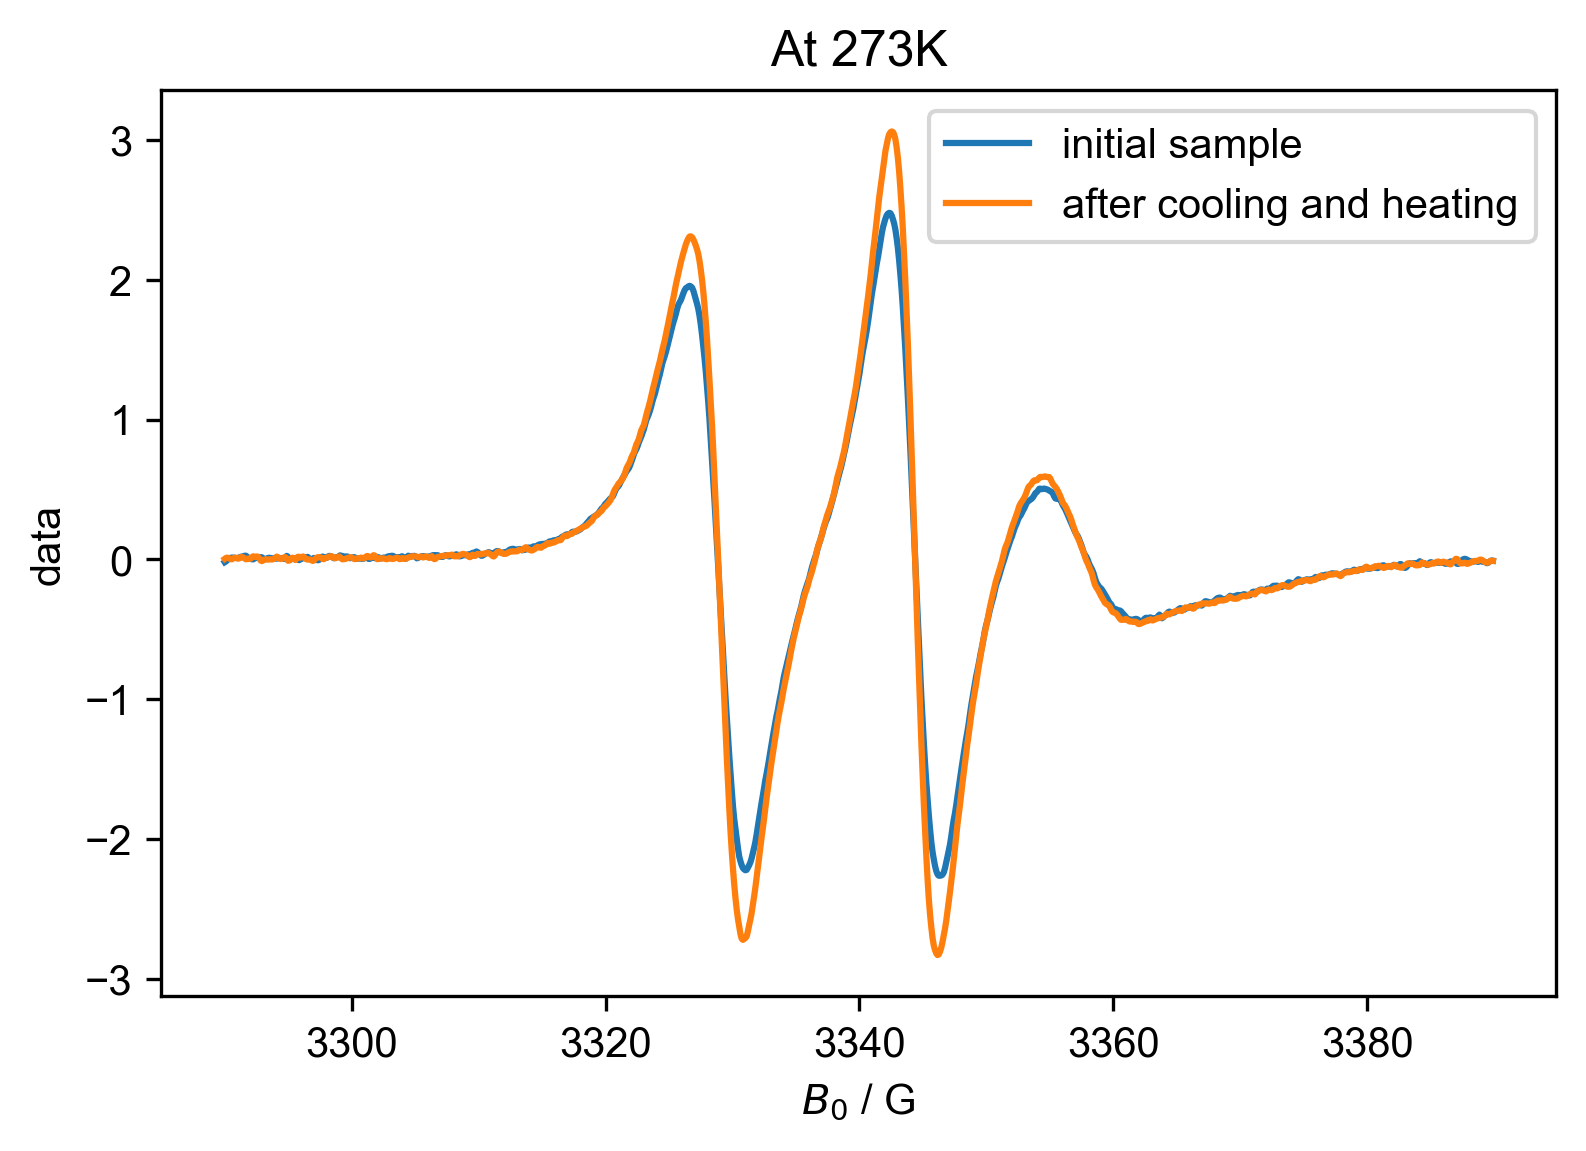

In [16]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[225.68  228.815 231.219 234.188 237.708 240.645 243.537 246.558 249.616
 252.775 255.642 258.786 261.692 264.507 267.528 270.939 273.59  276.576
 279.649 282.099]
[224.963 228.187 231.192 234.71  237.258 240.835 243.753 246.826 249.802
 252.776 255.696 258.366 261.418 264.351 267.347 270.683 273.604 276.348
 279.497 282.479]


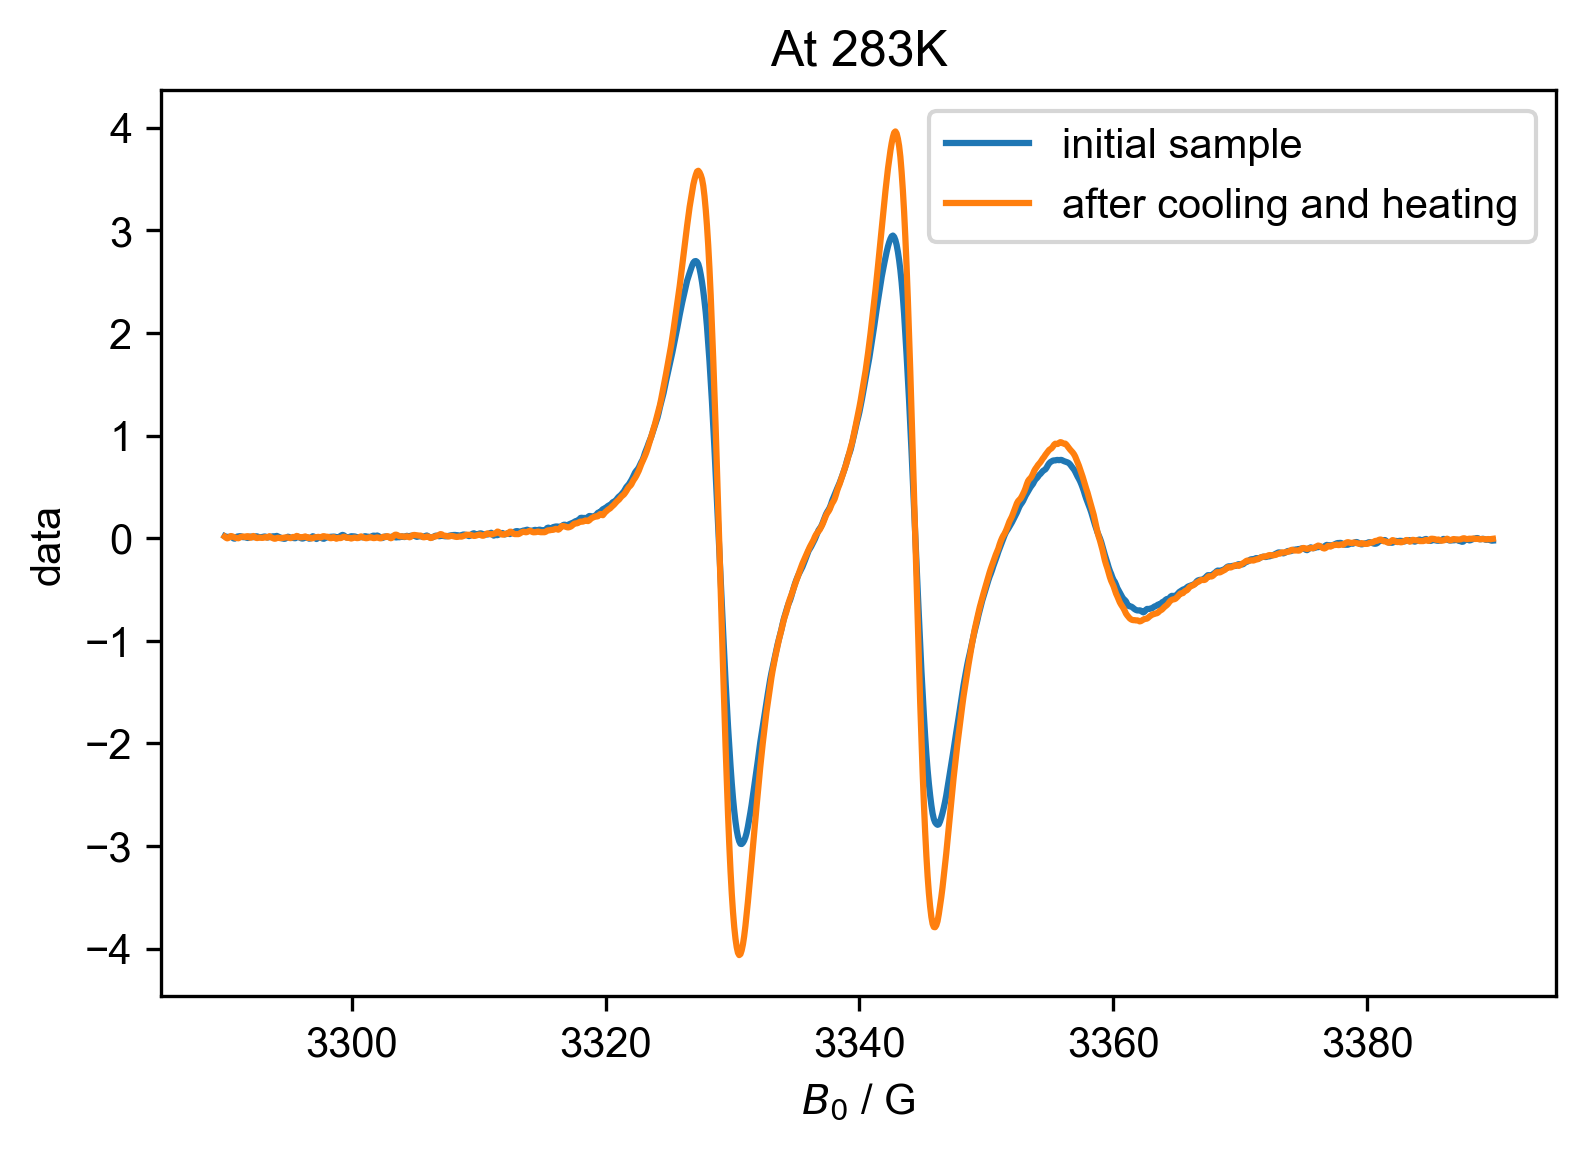

In [17]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [18]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()

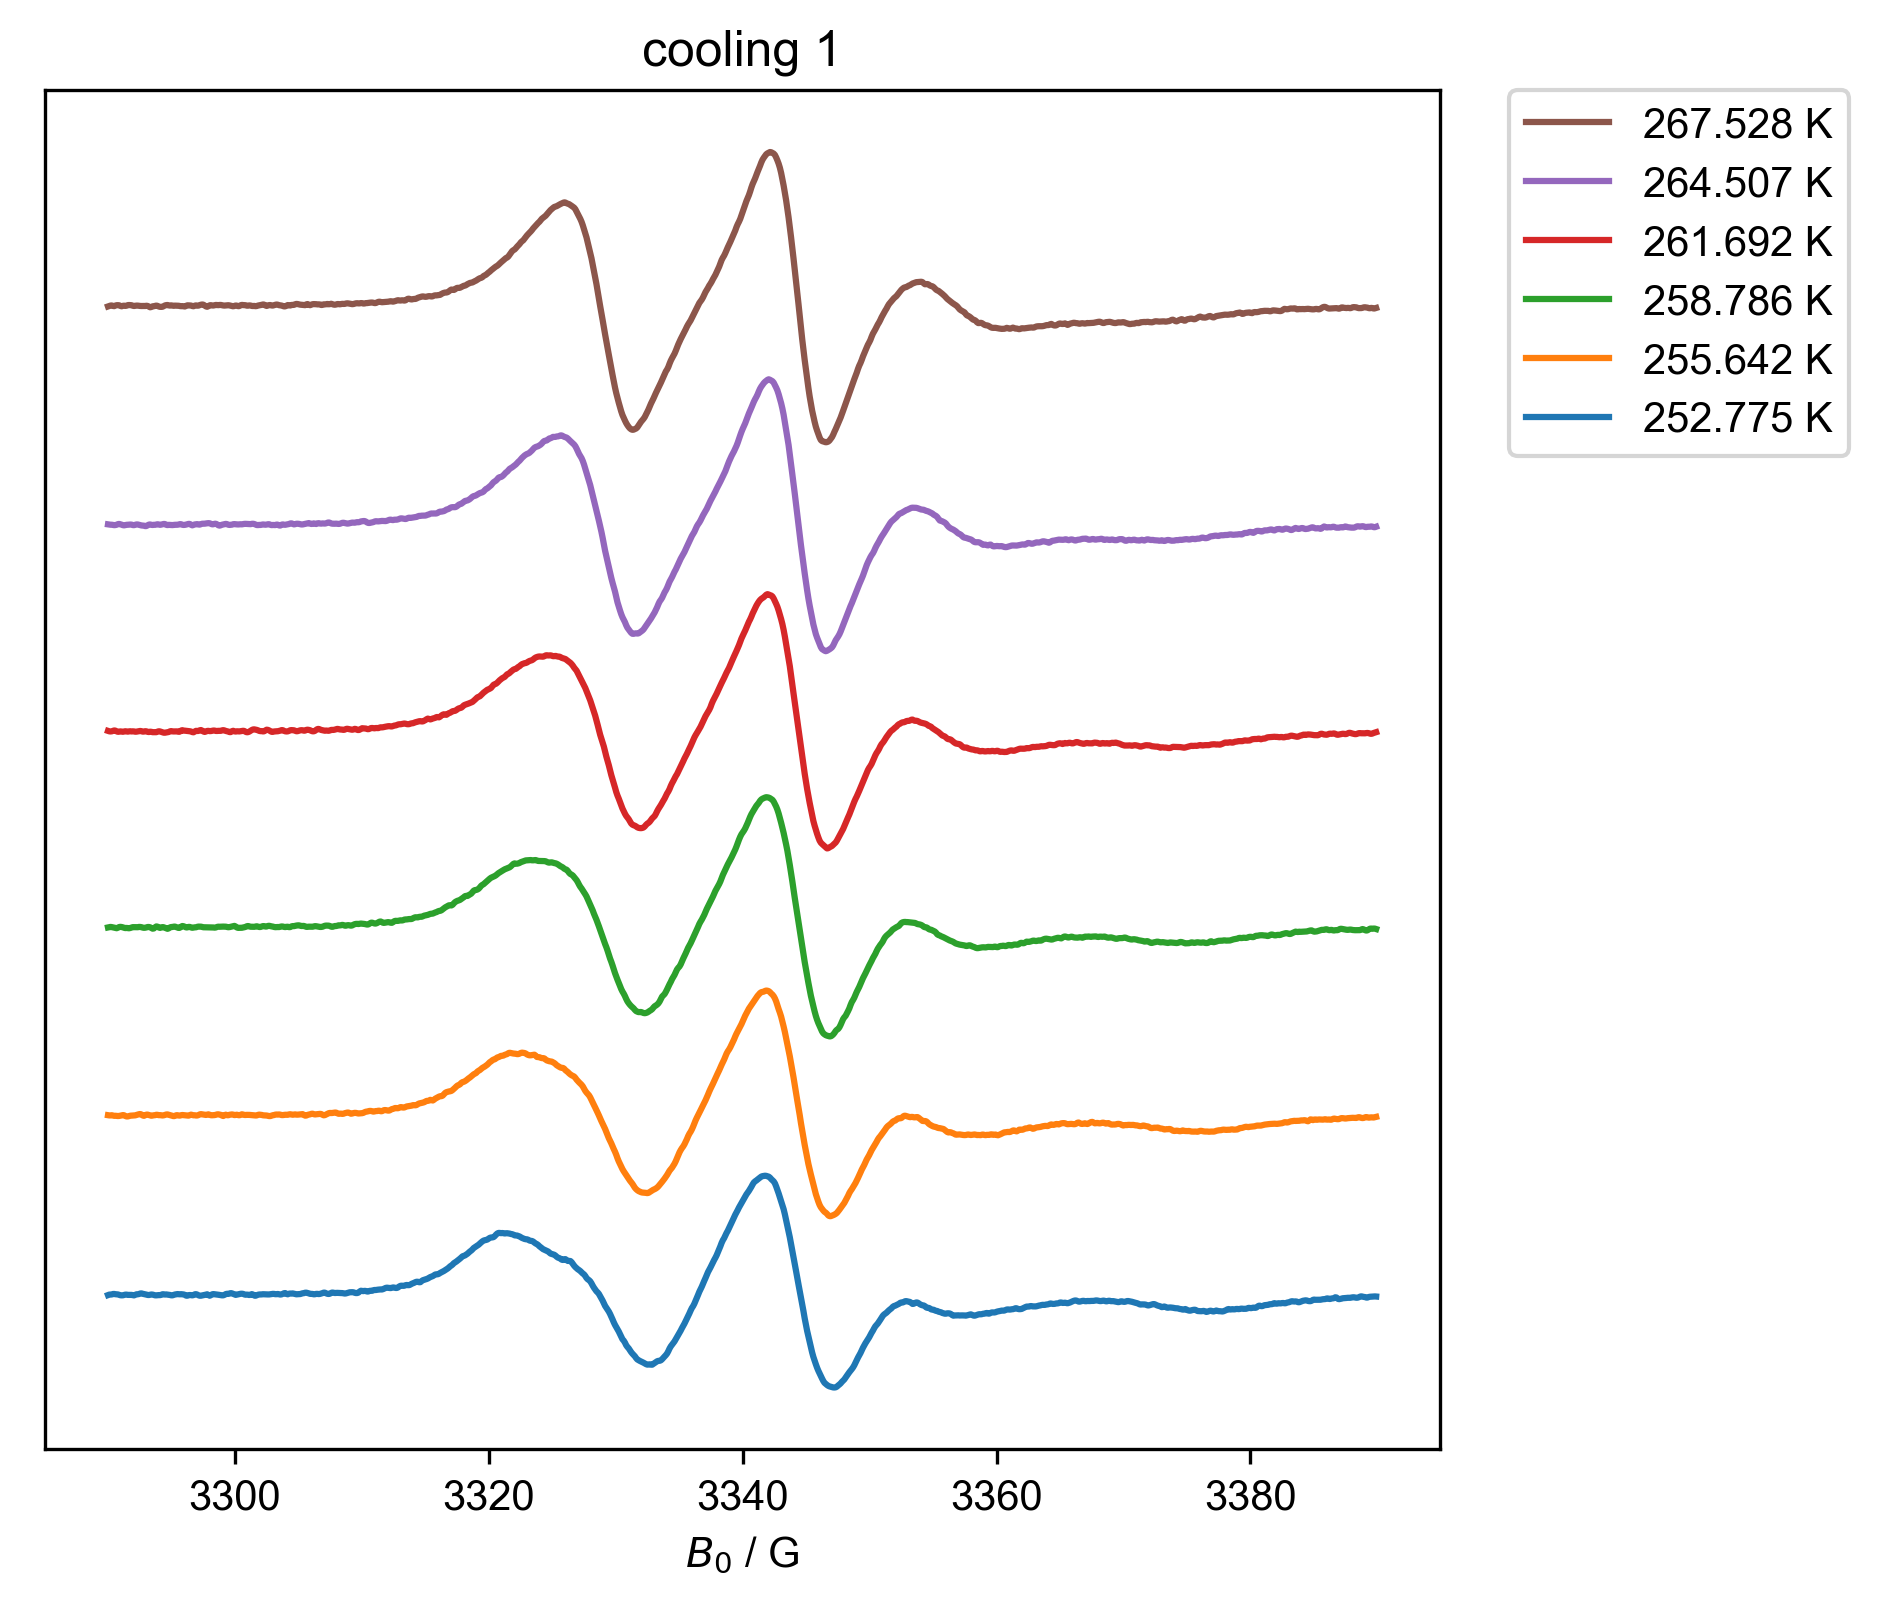

In [21]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("cooling 1", (250, 270))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

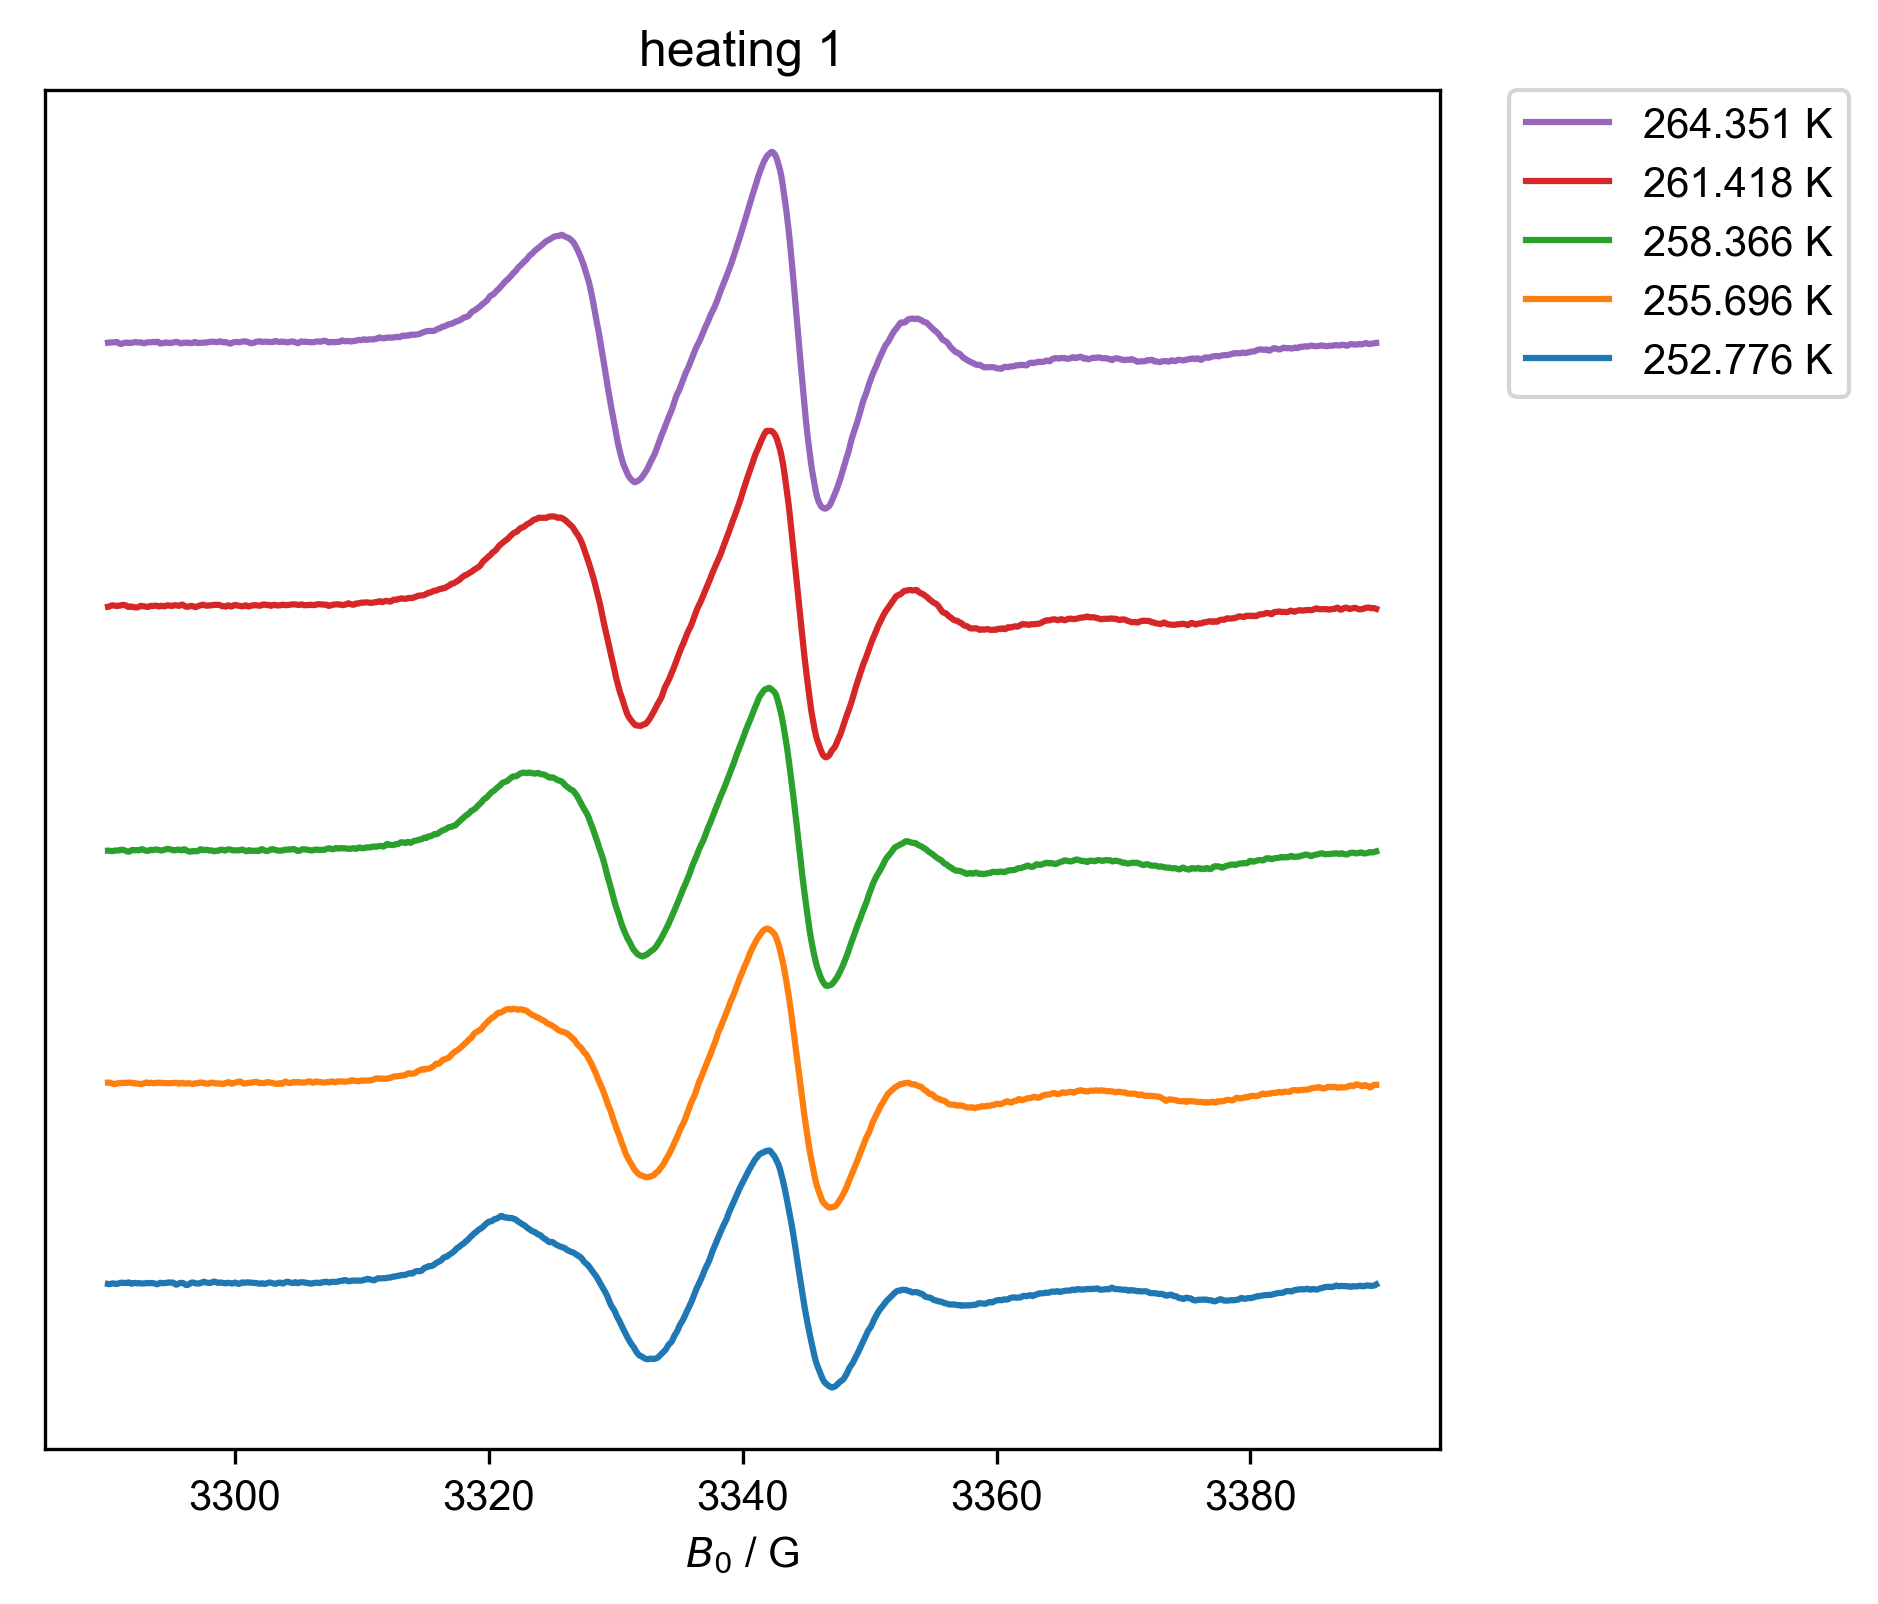

In [20]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("heating 1", (250, 265)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()